# Part A -- Contrast Stretching preprocessing pipeline

A classical preprocessing pipeline for cervical colposcopy images.

## Pipeline overview

* Step 1 -- Percentile-based contrast stretching (per RGB channel).
  Each channel is linearly rescaled so that the `LOW_PCT` percentile
  maps to 0 and the `HIGH_PCT` percentile maps to 255. Values outside
  `[low, high]` are clipped to `[0, 255]`. No quantization, no
  subsampling, no dithering.

## Output

The pipeline returns a **uint8 RGB image** (same shape as the input).
It is NOT a compression scheme. The output PNG is approximately the
same size as the input PNG. The pipeline is therefore evaluated as an
image-processing technique (distortion, stability, diagnostics), not
as a codec.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other.
* It does NOT demonstrate a clinical benefit on this single patient.


In [1]:
# ============================================================
# Cell 1.1 -- Combined imports & global setup
# ============================================================
import os, sys, glob, time, json, math, random, warnings, platform
from collections import defaultdict
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import ListedColormap

import pandas as pd
from scipy import ndimage, stats
from scipy.ndimage import gaussian_filter

try:
    from skimage.metrics import structural_similarity as _ssim_fn
    from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn
    _SKIMAGE_OK = True
except ImportError:
    _SKIMAGE_OK = False
    print("[warn] scikit-image not available -- SSIM/dE76 will be skipped.")

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Optional torch backend (not required, but used if available)
try:
    import torch
    _TORCH_OK = True
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)
        print(f"[gpu] PyTorch {torch.__version__} | CUDA device: "
              f"{torch.cuda.get_device_name(0)}")
    else:
        print(f"[gpu] PyTorch {torch.__version__} | CPU backend.")
except ImportError:
    _TORCH_OK = False
    DEVICE = None

# Output directory for results / CSV / JSON artefacts
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nContrast Stretching Validation Pipeline -- Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")


[gpu] PyTorch 2.5.1+cu121 | CUDA device: NVIDIA GeForce RTX 3050 Laptop GPU

Contrast Stretching Validation Pipeline -- Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Contrast Stretching (Step 1, the only preprocessing) ----
# Percentile-based linear stretch applied per RGB channel. The low
# percentile maps to 0 and the high percentile maps to 255; values
# outside [low, high] are clipped.
CS_LOW_PCT     = 2.0    # lower percentile (per channel)
CS_HIGH_PCT    = 98.0    # upper percentile (per channel)
CS_PER_CHANNEL = True    # if False, stretch on luminance only
CS_CLIP_OUTSIDE= True    # clip values outside [low, high] to [0, 255]
# Output is uint8 RGB; no quantization, so effective luma depth = 8 bits.
CS_LUMA_BITS   = 8.0

# ---- Synthetic fallback ----
SYNTHETIC_MODE = False   # set to True when no dataset is found

# ---- Validation batch ----
N_PER_CLASS_VALIDATE  = 5
SUBSET_PER_CLASS      = None

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  contrast stretch: low_pct={CS_LOW_PCT}, high_pct={CS_HIGH_PCT}, "
      f"per_channel={CS_PER_CHANNEL}, clip={CS_CLIP_OUTSIDE}")
print(f"  output luma depth = {CS_LUMA_BITS} bits/px (uint8, no quantization)")
print(f"  validation batch = {N_PER_CLASS_VALIDATE} imgs/class")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  contrast stretch: low_pct=2.0, high_pct=98.0, per_channel=True, clip=True
  output luma depth = 8.0 bits/px (uint8, no quantization)
  validation batch = 5 imgs/class


In [3]:
# ============================================================
# Cell 1.3 -- contrast_stretch + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def contrast_stretch(img_rgb, low_pct=None, high_pct=None,
                     per_channel=None, clip_outside=None):
    """Percentile-based linear contrast stretching.

    For each channel (or on the luminance if `per_channel=False`):
        scaled = (c - p_low) * 255 / (p_high - p_low)
    where p_low = percentile(c, low_pct) and p_high = percentile(c, high_pct).
    Values outside [p_low, p_high] are clipped to [0, 255] when
    `clip_outside=True` (default).

    Returns a uint8 RGB image of the same shape as the input.
    """
    if low_pct is None:     low_pct = CS_LOW_PCT
    if high_pct is None:    high_pct = CS_HIGH_PCT
    if per_channel is None: per_channel = CS_PER_CHANNEL
    if clip_outside is None: clip_outside = CS_CLIP_OUTSIDE

    img = np.asarray(img_rgb)
    if img.dtype != np.uint8:
        img = np.clip(img, 0, 255).astype(np.uint8)

    out = np.empty_like(img, dtype=np.uint8)

    if per_channel:
        channels = range(img.shape[-1])
        for ch in channels:
            c = img[..., ch].astype(np.float32)
            lo = float(np.percentile(c, low_pct))
            hi = float(np.percentile(c, high_pct))
            if hi - lo < 1e-6:
                out[..., ch] = img[..., ch]
                continue
            scaled = (c - lo) * (255.0 / (hi - lo))
            if clip_outside:
                scaled = np.clip(scaled, 0.0, 255.0)
            out[..., ch] = scaled.astype(np.uint8)
    else:
        # Stretch on luminance, apply the same gain/offset to all channels.
        g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
        lo = float(np.percentile(g, low_pct))
        hi = float(np.percentile(g, high_pct))
        if hi - lo < 1e-6:
            return img.copy()
        for ch in range(img.shape[-1]):
            c = img[..., ch].astype(np.float32)
            scaled = (c - lo) * (255.0 / (hi - lo))
            if clip_outside:
                scaled = np.clip(scaled, 0.0, 255.0)
            out[..., ch] = scaled.astype(np.uint8)
    return out


def preprocess_image(img_bgr, size=IMG_SIZE):
    """BGR -> RGB -> resize -> contrast stretch. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    img = contrast_stretch(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    apply contrast stretching. Case-insensitive dedupe by filename so the
    same physical file is never loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so the saliency-vs-GT
    evaluation has a real target.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (contrast stretch = ON)")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = contrast_stretch(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...  (contrast stretch = ON)
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


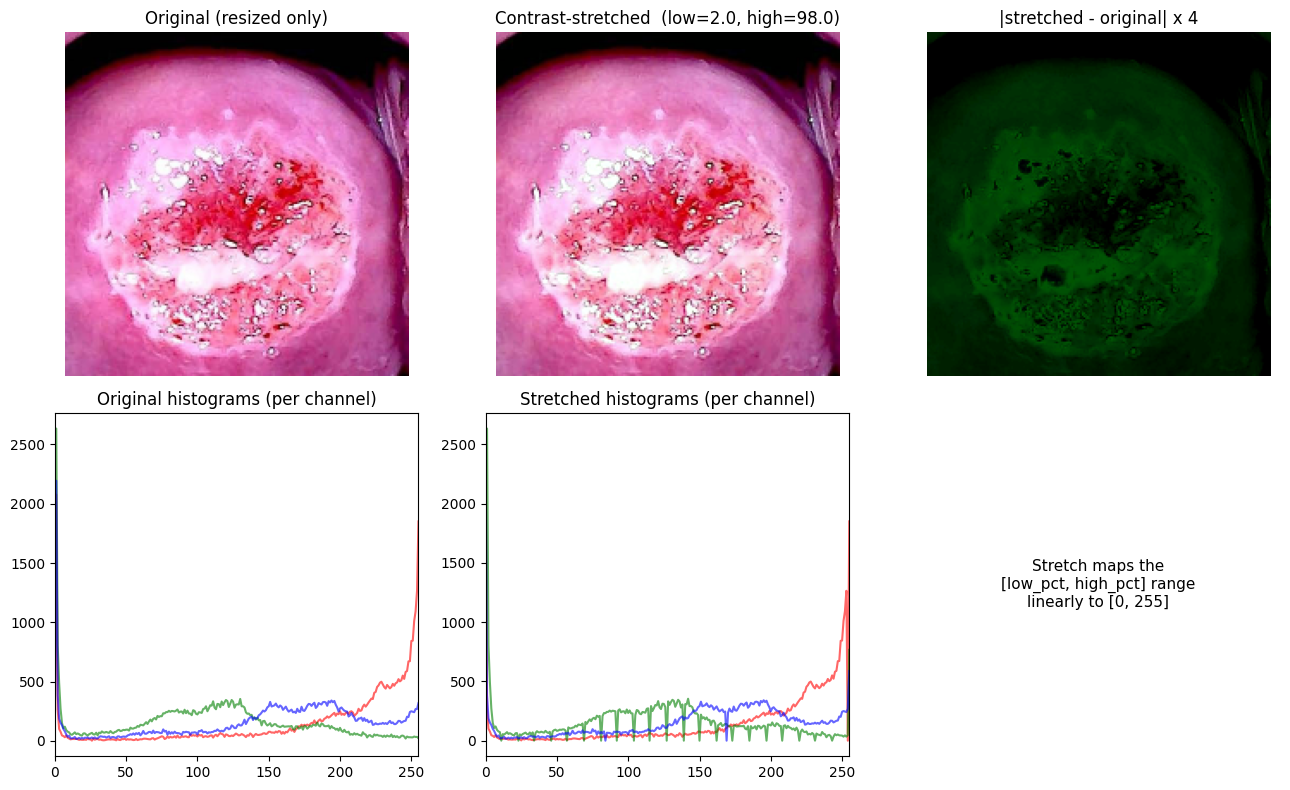

In [4]:
# ============================================================
# Cell 1.4 -- Contrast stretching before/after visualisation
# ============================================================
def show_contrast_stretch_effect(img_path=None, img_rgb=None):
    """Show original / contrast-stretched / histogram for a single image."""
    if img_rgb is None:
        raw_bgr = cv2.imread(img_path)
        if raw_bgr is None:
            print("Could not read", img_path); return
        raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        raw_resized = cv2.resize(raw_rgb, (IMG_SIZE, IMG_SIZE))
    else:
        raw_resized = img_rgb
    stretched = contrast_stretch(raw_resized)
    diff = np.clip(stretched.astype(np.int16) - raw_resized.astype(np.int16),
                   0, 255).astype(np.uint8)

    fig, ax = plt.subplots(2, 3, figsize=(13, 8))
    ax[0, 0].imshow(raw_resized);    ax[0, 0].set_title("Original (resized only)")
    ax[0, 0].axis("off")
    ax[0, 1].imshow(stretched);      ax[0, 1].set_title(
        f"Contrast-stretched  (low={CS_LOW_PCT}, high={CS_HIGH_PCT})")
    ax[0, 1].axis("off")
    ax[0, 2].imshow(diff * 4, cmap="gray")  # x4 to make the diff visible
    ax[0, 2].set_title("|stretched - original| x 4")
    ax[0, 2].axis("off")

    # Histograms per channel
    colors = ['r', 'g', 'b']
    for ch, c in enumerate(colors):
        hist_o = np.bincount(raw_resized[..., ch].ravel(), minlength=256)
        hist_s = np.bincount(stretched[..., ch].ravel(), minlength=256)
        ax[1, 0].plot(hist_o, color=c, alpha=0.6)
        ax[1, 1].plot(hist_s, color=c, alpha=0.6)
    ax[1, 0].set_title("Original histograms (per channel)")
    ax[1, 0].set_xlim(0, 255)
    ax[1, 1].set_title("Stretched histograms (per channel)")
    ax[1, 1].set_xlim(0, 255)
    ax[1, 2].axis("off")
    ax[1, 2].text(0.5, 0.5, "Stretch maps the\n[low_pct, high_pct] range\nlinearly to [0, 255]",
                  ha='center', va='center', transform=ax[1, 2].transAxes, fontsize=11)
    plt.tight_layout(); plt.show()


if len(X_raw) > 0:
    # Rebuild the original (un-stretched) image for the demo:
    # X_raw is already contrast-stretched, so for the visual diff we
    # rebuild the resize-only version from the first file or synthetic.
    if not SYNTHETIC_MODE and len(paths_raw) > 0 and os.path.isfile(paths_raw[0]):
        raw_bgr = cv2.imread(paths_raw[0])
        raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        raw_resized = cv2.resize(raw_rgb, (IMG_SIZE, IMG_SIZE))
        show_contrast_stretch_effect(img_rgb=raw_resized)
    else:
        # Synthetic demo: show stretching on a fresh synthetic image
        img_synth, _ = make_synthetic_image_and_mask(seed=SEED)
        show_contrast_stretch_effect(img_rgb=img_synth)
else:
    demo = np.random.RandomState(SEED).randint(40, 200, (200, 200, 3), dtype=np.uint8)
    demo[60:140, 60:140] = np.random.RandomState(SEED+1).randint(160, 255, (80, 80, 3), dtype=np.uint8)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(demo);               ax[0].set_title("Original");       ax[0].axis("off")
    ax[1].imshow(contrast_stretch(demo));      ax[1].set_title("Contrast-stretched");      ax[1].axis("off")
    plt.tight_layout(); plt.show()


In [5]:
# ============================================================
# Cell 2.1 -- Full Contrast Stretching preprocessing pipeline (RGB)
#
# Output type: this pipeline returns a uint8 RGB image of the same shape
# as the input. It is NOT a compression scheme. The output PNG is
# approximately the same size as the input PNG.
# ============================================================

def contrast_stretch_preprocess(img_rgb, return_artefacts=True, fov_mask=None):
    """Contrast Stretching preprocessing pipeline.

    Single step: percentile-based linear contrast stretching per RGB
    channel (or on luminance if CS_PER_CHANNEL=False).

    No quantization, no dithering, no chroma subsampling, no
    saliency mask, no bilateral filtering, no histogram matching.
    The output is uint8 RGB; the effective luma depth is 8 bits/px.

    Parameters
    ----------
    img_rgb : np.ndarray (H, W, 3) uint8
        Input RGB image.
    return_artefacts : bool
        If True, returns a dict with the stretched image and
        diagnostic artefacts (per-channel low/high percentiles, FOV
        mask if provided). If False, returns just the stretched uint8
        RGB image.
    fov_mask : np.ndarray (H, W) bool, optional
        Field-of-view mask. If provided, percentiles are computed
        inside the FOV only, so the black background does not skew
        the stretch range.
    """
    img_rgb = np.asarray(img_rgb)
    if img_rgb.dtype != np.uint8:
        img_rgb = np.clip(img_rgb, 0, 255).astype(np.uint8)

    # Optional FOV-masked percentile computation
    if fov_mask is not None:
        f = np.asarray(fov_mask, dtype=bool)
    else:
        f = None

    out = np.empty_like(img_rgb, dtype=np.uint8)
    artefacts = {
        "img_original": img_rgb,
        "fov_mask": f if f is not None else np.ones(img_rgb.shape[:2], dtype=bool),
        "low_pct": float(CS_LOW_PCT),
        "high_pct": float(CS_HIGH_PCT),
        "per_channel": bool(CS_PER_CHANNEL),
        "clip_outside": bool(CS_CLIP_OUTSIDE),
        "channel_low": [],
        "channel_high": [],
        "luma_bits": float(CS_LUMA_BITS),
    }

    if CS_PER_CHANNEL:
        for ch in range(img_rgb.shape[-1]):
            c = img_rgb[..., ch].astype(np.float32)
            if f is not None and f.any():
                c_in = c[f]
            else:
                c_in = c.ravel()
            lo = float(np.percentile(c_in, CS_LOW_PCT))
            hi = float(np.percentile(c_in, CS_HIGH_PCT))
            artefacts["channel_low"].append(lo)
            artefacts["channel_high"].append(hi)
            if hi - lo < 1e-6:
                out[..., ch] = img_rgb[..., ch]
                continue
            scaled = (c - lo) * (255.0 / (hi - lo))
            if CS_CLIP_OUTSIDE:
                scaled = np.clip(scaled, 0.0, 255.0)
            out[..., ch] = scaled.astype(np.uint8)
    else:
        # Stretch on luminance, apply the same gain/offset to all channels.
        g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
        if f is not None and f.any():
            g_in = g[f]
        else:
            g_in = g.ravel()
        lo = float(np.percentile(g_in, CS_LOW_PCT))
        hi = float(np.percentile(g_in, CS_HIGH_PCT))
        for ch in range(img_rgb.shape[-1]):
            c = img_rgb[..., ch].astype(np.float32)
            scaled = (c - lo) * (255.0 / (hi - lo))
            if CS_CLIP_OUTSIDE:
                scaled = np.clip(scaled, 0.0, 255.0)
            out[..., ch] = scaled.astype(np.uint8)
        artefacts["channel_low"] = [lo, lo, lo]
        artefacts["channel_high"] = [hi, hi, hi]

    artefacts["img_processed"] = out
    if return_artefacts:
        return artefacts
    return out


# --- Sanity check on the first loaded image ---
if len(X_raw) > 0:
    _art = contrast_stretch_preprocess(X_raw[0], return_artefacts=True)
    print(f"Sanity check on image 0:")
    print(f"  shape: {_art['img_original'].shape} -> {_art['img_processed'].shape}")
    print(f"  per-channel low/high (pct={CS_LOW_PCT}/{CS_HIGH_PCT}):")
    for ch, (lo, hi) in enumerate(zip(_art["channel_low"], _art["channel_high"])):
        print(f"    channel {ch}: low={lo:.2f}, high={hi:.2f}, range={hi-lo:.2f}")
    print(f"  luma bits = {_art['luma_bits']}")
else:
    print("[warn] No images loaded; cannot run sanity check.")


Sanity check on image 0:
  shape: (200, 200, 3) -> (200, 200, 3)
  per-channel low/high (pct=2.0/98.0):
    channel 0: low=0.00, high=255.00, range=255.00
    channel 1: low=0.00, high=254.00, range=254.00
    channel 2: low=0.00, high=254.00, range=254.00
  luma bits = 8.0


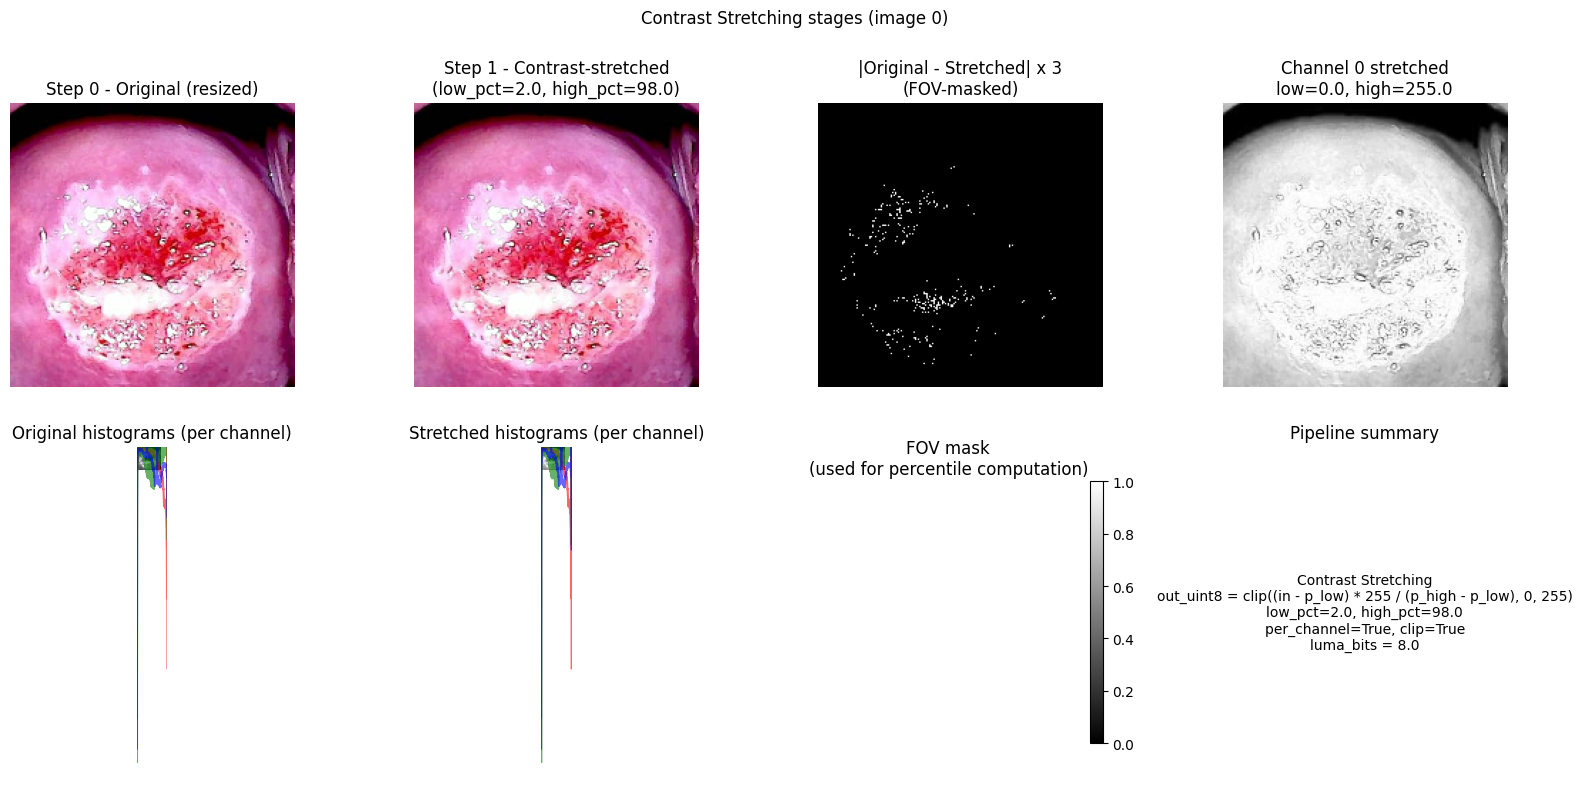

In [6]:
# ============================================================
# Cell 2.2 -- Visualise Contrast Stretching stages
# ============================================================
def show_contrast_stretch_stages(rgb_image, title=""):
    """Show original / stretched / diff / histograms / per-channel stretches."""
    art = contrast_stretch_preprocess(rgb_image, return_artefacts=True)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.ravel()

    axes[0].imshow(art["img_original"])
    axes[0].set_title("Step 0 - Original (resized)")
    axes[0].axis('off')

    axes[1].imshow(art["img_processed"])
    axes[1].set_title(f"Step 1 - Contrast-stretched\n"
                      f"(low_pct={art['low_pct']}, high_pct={art['high_pct']})")
    axes[1].axis('off')

    # |Original - Stretched| x 3 (FOV-masked)
    diff_rgb = np.abs(art["img_original"].astype(np.float32)
                      - art["img_processed"].astype(np.float32))
    diff_gray = diff_rgb.mean(axis=-1)
    fov = art["fov_mask"]
    diff_gray[~fov] = 0.0
    diff_scaled = diff_gray * 3.0
    if fov.any():
        p99 = float(np.percentile(diff_scaled[fov], 99))
    else:
        p99 = 1e-6
    p99 = max(p99, 1e-6)
    diff_norm = np.clip(diff_scaled / p99, 0.0, 1.0)
    axes[2].imshow(diff_norm, cmap='gray', vmin=0.0, vmax=1.0)
    axes[2].set_title("|Original - Stretched| x 3\n(FOV-masked)")
    axes[2].axis('off')

    # Per-channel stretched grayscale (R, G, B)
    for ch in range(3):
        axes[3 + ch].imshow(art["img_processed"][..., ch], cmap='gray', vmin=0, vmax=255)
        lo = art["channel_low"][ch] if ch < len(art["channel_low"]) else float('nan')
        hi = art["channel_high"][ch] if ch < len(art["channel_high"]) else float('nan')
        axes[3 + ch].set_title(f"Channel {ch} stretched\nlow={lo:.1f}, high={hi:.1f}")
        axes[3 + ch].axis('off')

    # Second row: histograms
    colors = ['r', 'g', 'b']
    for ch, c in enumerate(colors):
        hist_o = np.bincount(art["img_original"][..., ch].ravel(), minlength=256)
        hist_s = np.bincount(art["img_processed"][..., ch].ravel(), minlength=256)
        axes[4].plot(hist_o, color=c, alpha=0.6)
        axes[5].plot(hist_s, color=c, alpha=0.6)
    axes[4].set_title("Original histograms (per channel)")
    axes[4].set_xlim(0, 255)
    axes[5].set_title("Stretched histograms (per channel)")
    axes[5].set_xlim(0, 255)

    # FOV mask
    im_fov = axes[6].imshow(art["fov_mask"].astype(np.float32), cmap='gray', vmin=0, vmax=1)
    axes[6].set_title("FOV mask\n(used for percentile computation)")
    axes[6].axis('off')
    plt.colorbar(im_fov, ax=axes[6], fraction=0.046, pad=0.04)

    axes[7].text(0.5, 0.5,
                 "Contrast Stretching\n"
                 "out_uint8 = clip((in - p_low) * 255 / (p_high - p_low), 0, 255)\n"
                 f"low_pct={art['low_pct']}, high_pct={art['high_pct']}\n"
                 f"per_channel={art['per_channel']}, clip={art['clip_outside']}\n"
                 f"luma_bits = {art['luma_bits']}",
                 ha='center', va='center', transform=axes[7].transAxes, fontsize=10)
    axes[7].axis('off')
    axes[7].set_title("Pipeline summary")

    plt.suptitle(title or "Contrast Stretching stages")
    plt.tight_layout(); plt.show()


if len(X_raw) > 0:
    show_contrast_stretch_stages(X_raw[0], title="Contrast Stretching stages (image 0)")


# Bridge -- hand off Contrast Stretching preprocessing to Step 4

Step 4 expects five variables from Step 1:

| Step-4 name | Meaning                                   | Source in this notebook                 |
|-------------|-------------------------------------------|----------------------------------------|
| `X_base`    | (N,200,200,3) uint8 RGB, **stretched**    | `X_raw` from the loader (contrast-stretched) |
| `X_raw`     | (N,200,200,3) uint8 RGB, **resize-only**  | reloaded with `preprocess_image` (resize, no stretch) |
| `image_ids` | unique id per image                       | sequential `img_NNNN`                  |
| `masks`     | clinician lesion masks (OPTIONAL)         | `masks_raw` from the loader            |
| `patient`   | patient id (OPTIONAL)                     | `None`                                 |

We also register the technique:

* `CS_DEFAULTS` -- empty dict (the pipeline uses fixed module-level config; **no tuning on a single patient**).
* `cs_apply(img, params, seed) -> uint8 RGB image` -- wraps `contrast_stretch_preprocess(img, return_artefacts=False)`.
  Determinism: contrast stretching is fully deterministic, the `seed` is accepted only for API symmetry with the validator.


In [7]:
# ============================================================
# Bridge -- hand off Contrast Stretching preprocessing to Step 4.
# ============================================================

def _load_dataset_resize_only():
    """Reload the dataset WITHOUT contrast stretching so the validator
    has a true resize-only FOV source. Used only for FOV mask computation."""
    X, y, paths, masks = [], [], [], []
    for cls in CLASSES:
        folder = os.path.join(DATASET_ROOT, cls)
        if not os.path.isdir(folder):
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                continue
            seen.add(key)
            files.append(p)
        if SUBSET_PER_CLASS:
            files = files[:SUBSET_PER_CLASS]
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
            X.append(img); y.append(cls); paths.append(p)
    if not X:
        return None
    return (np.stack(X).astype(np.uint8), np.array(y), paths)


# --- Step-1 contrast-stretched stack becomes the validator's X_base ---
X_base = X_raw.copy()                       # contrast-stretched, 200x200, uint8 RGB
_masks = masks_raw.copy()                   # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))],
                     dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# --- Reload the SAME images WITHOUT contrast stretching -> X_raw ---
if not SYNTHETIC_MODE:
    out = _load_dataset_resize_only()
    if out is None or len(out[0]) == 0:
        X_raw_unsharp = X_base.copy()
    else:
        X_raw_unsharp, _, _ = out
        if len(X_raw_unsharp) != len(X_base):
            print(f"[bridge] X_raw_unsharp count ({len(X_raw_unsharp)}) != "
                  f"X_base count ({len(X_base)}); falling back to X_base.")
            X_raw_unsharp = X_base.copy()
else:
    # Synthetic path: rebuild the same synthetic images WITHOUT the
    # contrast-stretch pass, so the validator gets a true resize-only FOV source.
    _xs = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, _ = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            _xs.append(img)
    X_raw_unsharp = np.stack(_xs).astype(np.uint8)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw_unsharp[i] = np.clip(
            X_raw_unsharp[i].astype(np.int32) + np.array([dr, dg, db]),
            0, 255,
        ).astype(np.uint8)

# Step 4 expects the name `X_raw` for the resize-only stack.
X_raw = X_raw_unsharp

# Final shape assertions
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert X_raw.shape == X_base.shape, \
    f"X_raw {X_raw.shape} != X_base {X_base.shape} after bridge"
assert len(image_ids) == len(X_base) == len(X_raw), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)} X_raw={len(X_raw)}"
assert _masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {_masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

# Register the technique as `cs_apply` for the validator
CS_DEFAULTS = {}

def cs_apply(img, params, seed=42):
    """Wrapper used by the validator. params is ignored (the pipeline uses
    module-level config). seed is accepted for API symmetry; the pipeline
    is fully deterministic."""
    return contrast_stretch_preprocess(img, return_artefacts=False)

print(f"Bridge OK: X_base={X_base.shape} (contrast-stretched), "
      f"X_raw={X_raw.shape} (resize-only), "
      f"masks={_masks.shape}, n_ids={len(image_ids)}")
print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")


Bridge OK: X_base=(128, 200, 200, 3) (contrast-stretched), X_raw=(128, 200, 200, 3) (resize-only), masks=(128, 200, 200), n_ids=128
SYNTHETIC_MODE = False


# Part B -- Step 4 rewrite: table-only validation with 11 metrics

Single-patient, 7 distinct clusters (dHash), 128 frames. The frames are
NOT independent. Descriptive only -- no p-values, no robustness or
population claims.

**Technique:** Contrast Stretching (percentile-based per-channel linear
stretch, `low_pct=2`, `high_pct=98`).

**Metrics:** 11 metrics in 4 groups (fidelity, colour, diagnostic
structure, quality, cost). All computed inside the FOV mask only, per
image, against the ORIGINAL (resize-only) image.

  * PSNR (dB)            -- m1  (up)
  * SSIM                 -- m2  (up)
  * CIE76 dE            -- m3  (down)
  * a* correlation       -- m4  (up)
  * |mean a* shift|      -- m5  (down)
  * Vessel Dice          -- m6  (up)
  * Edge IoU             -- m7  (up)
  * Sharpness ratio      -- m8  (neutral)
  * Noise ratio          -- m9  (down)
  * Saturation ratio     -- m10 (neutral)
  * Luma bits            -- m11 (down)

Time (m12) is NOT reported in this notebook.


In [8]:
# ============================================================
# Step 4.1 -- Freeze inputs: load 128 frames, FOV masks, cluster ids.
# ============================================================
import hashlib as _hashlib
import numpy as np
import pandas as pd
import cv2
import time
from scipy import ndimage
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

# ---- dHash for clustering (same as the old validator) ----
def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

# ---- FOV mask (convex-hull filled, same as Part A) ----
def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask (convex-hull filled, same as Part A's _compute_fov_local)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Build the cache from X_base (Part A's contrast-stretched stack) ----
images = X_base                      # (N, 200, 200, 3) uint8 RGB, contrast-stretched
images_raw = X_raw                   # (N, 200, 200, 3) uint8 RGB, resize-only (for FOV)
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([_compute_fov_step4(images_raw[i]) for i in range(n_images)])

# dHash clustering (same as the old validator)
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    h_bytes = h.tobytes()
    if h_bytes in {hs[j].tobytes() for j in range(i)}:
        # Match an earlier cluster
        for j in range(i):
            if (hs[j] == h).all():
                cluster_ids[i] = cluster_ids[j]
                break
    else:
        cluster_ids[i] = _next
        _next += 1

print(f"Loaded {n_images} images, {len(np.unique(cluster_ids))} clusters (dHash).")
print(f"  cluster sizes: {[int((cluster_ids == c).sum()) for c in np.unique(cluster_ids)]}")

# cache_hash: a stable identifier for this Part A freeze (so Step 4
# can detect that Part A changed and refuse to load stale per-image CSVs).
_h = _hashlib.sha1()
_h.update(b"contrast_stretching_v1")
_h.update(np.ascontiguousarray(images).tobytes())
_h.update(str(CS_LOW_PCT).encode() + b"|" + str(CS_HIGH_PCT).encode())
cache_hash = _h.hexdigest()[:12]
print(f"cache_hash = {cache_hash}  (Contrast Stretching, frozen)")


Loaded 128 images, 12 clusters (dHash).
  cluster sizes: [8, 8, 24, 8, 16, 16, 8, 8, 8, 8, 8, 8]
cache_hash = c448bbd243bb  (Contrast Stretching, frozen)


In [9]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions. Computes 11 metrics
#              inside the FOV only (no Time column).
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    try:
        from skimage.filters import frangi
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes the Dice coefficient 2*|A&B|/(|A|+|B|).
    """
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    size_o = float(b_o.sum())
    size_p = float(b_p.sum())
    denom = size_o + size_p
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/glare mask (same as the old validator)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def step4_validator(original, processed, fov_mask):
    """Compute 11 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                         up
      m2  SSIM                              up
      m3  CIE76 dE                          down
      m4  a* correlation                     up
      m5  |mean a* shift|                    down
      m6  Vessel Dice                        up
      m7  Edge IoU                           up
      m8  Sharpness ratio (out/in)           neutral
      m9  Noise ratio (out/in)               down
      m10 Saturation ratio (out/in)          neutral
      m11 Bits/px (luma depth)               down (set externally)

    m11 (Luma bits) is NOT computed here; it is set by the caller
    (the bit depth depends on the technique; for contrast stretching
    it is fixed at 8 bits/px).
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    if _SKIMAGE_OK:
        ssim_map = _ssim_fn(original, processed, channel_axis=2,
                             full=True, data_range=255)[1]
        m2 = float(ssim_map.mean(2)[f].mean())
    else:
        m2 = float('nan')
    # m3: CIE76 dE
    if _SKIMAGE_OK:
        m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    else:
        m3 = float('nan')
    # m4: a* correlation
    if _SKIMAGE_OK:
        lab_o = _rgb2lab_fn(original)
        lab_p = _rgb2lab_fn(processed)
        m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
        # m5: |mean a* shift|
        a_o = float(lab_o[..., 1][f].mean())
        a_p = float(lab_p[..., 1][f].mean())
        m5 = abs(a_p - a_o)
    else:
        m4 = float('nan'); m5 = float('nan')
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                   cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular).
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)
    # m11: set by the caller (Luma bits)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10)

# ---- Metric metadata (name, group, better direction) ----
# 11 metrics only -- NO Time (m12).
METRIC_META = [
    ("m1",  "PSNR (dB)",          "fidelity",  "up"),
    ("m2",  "SSIM",               "fidelity",  "up"),
    ("m3",  "dE76",               "colour",    "down"),
    ("m4",  "a* corr",            "colour",    "up"),
    ("m5",  "|a* shift|",         "colour",    "down"),
    ("m6",  "Vessel Dice",        "structure", "up"),
    ("m7",  "Edge IoU",           "structure", "up"),
    ("m8",  "Sharpness ratio",    "quality",   "neutral"),
    ("m9",  "Noise ratio",        "quality",   "down"),
    ("m10", "Saturation ratio",   "quality",   "neutral"),
    ("m11", "Luma bits",           "cost",      "down"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print(f"step4_validator ready: {len(METRIC_KEYS)} metrics (m1..m11). No Time (m12).")


step4_validator ready: 11 metrics (m1..m11). No Time (m12).


In [10]:
# ============================================================
# Step 4.3 -- Compute 11 metrics for Contrast Stretching.
#             Write per-image CSV. Cache processed images.
# ============================================================
import os as _os
import glob as _glob

for _old in _glob.glob("results_*.csv"):
    _os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE = "ContrastStretching"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB
artefacts_cache = {}   # (technique, image_idx) -> artefacts dict

def _luma_bits_from_artefacts(art):
    """Luma bits/px for contrast stretching. The output is uint8 with no
    quantization, so the effective luma depth is fixed at 8 bits/px."""
    return float(art.get("luma_bits", CS_LUMA_BITS))

rows = []
for i in range(n_images):
    orig = images_raw[i]                # resize-only original (the reference)
    fov_i = fov[i]
    t0 = time.perf_counter()
    proc = cs_apply(orig, {}, seed=42 + i)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    _art = contrast_stretch_preprocess(orig, return_artefacts=True, fov_mask=fov_i)
    m11_val = _luma_bits_from_artefacts(_art)
    m = step4_validator(orig, proc, fov_i)
    m["m11"] = m11_val              # Luma bits (fixed at 8.0 for uint8)
    m["elapsed_ms"] = elapsed_ms    # diagnostics only, not in METRIC_KEYS
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    artefacts_cache[(TECHNIQUE, i)] = _art
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_cs = pd.DataFrame(rows)
df_cs.to_csv(f"results_{TECHNIQUE}.csv", index=False)
print(f"Wrote results_{TECHNIQUE}.csv ({len(df_cs)} rows)")
print(f"  Mean luma bits = {df_cs['m11'].mean():.3f}")
print(f"  Mean PSNR = {df_cs['m1'].mean():.2f} dB")
print(f"  Mean SSIM = {df_cs['m2'].mean():.4f}")
print(f"  Mean dE76 = {df_cs['m3'].mean():.3f}")
print(f"  Mean time = {df_cs['elapsed_ms'].mean():.2f} ms (diagnostic only)")


  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results_ContrastStretching.csv (128 rows)
  Mean luma bits = 8.000
  Mean PSNR = 27.78 dB
  Mean SSIM = 0.9702
  Mean dE76 = 8.801
  Mean time = 3.41 ms (diagnostic only)


In [11]:
# ============================================================
# Step 4.4 -- Reference row: Identity (no preprocessing).
#             Useful as the ideal reference for the metrics.
# ============================================================
rows_id = []
for i in range(n_images):
    orig = images_raw[i]
    fov_i = fov[i]
    proc = orig.copy()                       # identity: no preprocessing
    processed_cache[("Identity", i)] = proc.copy()
    m = step4_validator(orig, proc, fov_i)
    m["m11"] = float(CS_LUMA_BITS)           # uint8 -> 8 bits/px
    m["elapsed_ms"] = 0.0
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)

df_id = pd.DataFrame(rows_id)
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows)")
print(f"  Identity mean PSNR = {df_id['m1'].mean():.2f} dB (should be ~inf / very high)")
print(f"  Identity mean SSIM = {df_id['m2'].mean():.4f} (should be 1.0)")
print(f"  Identity mean dE76 = {df_id['m3'].mean():.6f} (should be 0.0)")


Wrote results_Identity.csv (128 rows)
  Identity mean PSNR = 148.13 dB (should be ~inf / very high)
  Identity mean SSIM = 1.0000 (should be 1.0)
  Identity mean dE76 = 0.000000 (should be 0.0)


In [12]:
# ============================================================
# Step 4.5 -- Merge cell: concatenate all technique CSVs. Assert
#              each technique has the same number of rows and the
#              same cluster ids. Assert no NaNs (or list them).
# Uses a FIXED list of CSV names (not glob) to prevent stale files
# from earlier runs leaking into the tables.
# ============================================================

_csv_names = [
    f"results_{TECHNIQUE}.csv",
    "results_Identity.csv",
]
print(f"Reading {len(_csv_names)} CSV files (fixed list, not glob)")
dfs = []
for f in _csv_names:
    _df = pd.read_csv(f)
    tech = _df["technique"].iloc[0] if len(_df) > 0 else f
    assert len(_df) == n_images, f"{f} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{f} cluster ids differ"
    dfs.append(_df)
    print(f"  {f}: {len(_df)} rows, technique = {tech}")

merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques")

# Hard assert: no NaN in any numeric column (metrics only).
_all_numeric_cols = METRIC_KEYS
_all_numeric_cols = [c for c in _all_numeric_cols if c in merged.columns]
_nan_cols = {}
for col in _all_numeric_cols:
    n_nan = merged[col].isna().sum()
    if n_nan > 0:
        _nan_cols[col] = n_nan
if len(_nan_cols) > 0:
    print(f"[warn] NaN values found: {_nan_cols}")
else:
    print("No NaN values in any numeric column (m1..m11).")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")


Reading 2 CSV files (fixed list, not glob)
  results_ContrastStretching.csv: 128 rows, technique = ContrastStretching
  results_Identity.csv: 128 rows, technique = Identity
Merged: 256 rows, 2 techniques
No NaN values in any numeric column (m1..m11).
Techniques: ['ContrastStretching', 'Identity']


In [13]:
# ============================================================
# Step 4.6 -- Aggregation: average within each cluster first, then
#              across clusters. 95% CI from a cluster bootstrap
#              (n_clusters clusters, 2000 resamples, fixed seed).
#              Label: "within-patient, n clusters, not a population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters (2000 resamples).
    Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI.
    """
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

# Compute the cluster-weighted mean and CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
n_clusters = len(np.unique(cluster_ids))
print(f"Aggregation done (cluster-weighted mean + 95% CI).")
print(f"  WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.")


Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, 12 clusters, NOT a population CI.


In [14]:
# ============================================================
# Step 4.7 -- Statistics: Contrast Stretching vs Identity, per metric.
#              Uses paired difference per cluster + bootstrap CI.
#              Reports "CI excludes 0: yes/no".
#              Descriptive, no significance claim.
# ============================================================

def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=2000, seed=42):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm = ref_df.groupby("cluster_id")[metric_key].mean()
    # Align on cluster id
    diff = (tech_cm - ref_cm).dropna().values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes

# All 11 metrics for the paired comparison (skip Identity-vs-itself).
stat_rows = []
cs_df = merged[merged["technique"] == "ContrastStretching"]
id_df = merged[merged["technique"] == "Identity"]

for mk in METRIC_KEYS:
    # ContrastStretching vs Identity
    md, lo, hi, ex = _paired_cluster_diff_ci(cs_df, id_df, mk)
    stat_rows.append({
        "metric": METRIC_NAMES[mk],
        "comparison": "ContrastStretching vs Identity",
        "mean_diff": md,
        "ci_lo": lo,
        "ci_hi": hi,
        "CI_excludes_0": "yes" if ex else "no",
    })

stat_df = pd.DataFrame(stat_rows)
print("Statistics done. ContrastStretching vs Identity, all 11 metrics.")
print("  Descriptive, no significance claim. Within-patient, "
      f"{n_clusters} clusters.")


Statistics done. ContrastStretching vs Identity, all 11 metrics.
  Descriptive, no significance claim. Within-patient, 12 clusters.


In [15]:
# ============================================================
# Print tables T1 (main) and T2 (stats).
# T2 (ranks) and T3 (Pareto) removed: only 2 techniques -> not meaningful.
# ============================================================

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- T1 MAIN ----
print("=" * 120)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, "
      f"{n_clusters} clusters, NOT a population CI)")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 120)
t1_display_keys = [mk for mk in METRIC_KEYS]   # show all 11
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in t1_display_keys:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        if mk == "m1" and tech == "Identity":
            # PSNR for identity is essentially infinity (MSE=0 -> +inf dB).
            row[METRIC_NAMES[mk]] = "inf (ideal)"
        elif mk == "m3" and tech == "Identity":
            row[METRIC_NAMES[mk]] = "0.000 (ideal)"
        elif mk == "m5" and tech == "Identity":
            row[METRIC_NAMES[mk]] = "0.000 (ideal)"
        elif mk in ("m8", "m9", "m10") and tech == "Identity":
            row[METRIC_NAMES[mk]] = "1.000 (ideal)"
        else:
            row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in t1_display_keys}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T2 STATS ----
print()
print("=" * 120)
print("T2 STATS  (ContrastStretching vs Identity, paired-cluster bootstrap, 2000 resamples)")
print("  Descriptive, no significance claim. CI excludes 0 = directional change.")
print("=" * 120)
print(stat_df.to_string(index=False))

# ---- T3 SUMMARY ----
print()
print("=" * 120)
print("T3 SUMMARY  (Contrast Stretching pipeline configuration)")
print("=" * 120)
print(f"  Technique:          ContrastStretching")
print(f"  low_pct:            {CS_LOW_PCT}")
print(f"  high_pct:           {CS_HIGH_PCT}")
print(f"  per_channel:        {CS_PER_CHANNEL}")
print(f"  clip_outside:       {CS_CLIP_OUTSIDE}")
print(f"  luma_bits (m11):    {CS_LUMA_BITS} (uint8, no quantization)")
print(f"  cache_hash:         {cache_hash}")
print(f"  n_images:           {n_images}")
print(f"  n_clusters:         {n_clusters}")
print(f"  metrics:           {len(METRIC_KEYS)} (m1..m11, NO Time)")


T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 12 clusters, NOT a population CI)
  The 128 frames are NOT independent (12 distinct clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
                              PSNR (dB) (^)              SSIM (^)               dE76 (v)           a* corr (^)        |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (v)
technique                                                                                                                                                                                                                                                               
ContrastStretching  27.348 [24.659, 29.972]  0.968 [0.950, 0.985]  9.394 [7.195, 11.724]  0.948 [0.920, 0.974]  7.826 [5.988, 9.762]  0.974 [0.968, 0.980]  0.835 [0.794, 0.872]  1.367 [1.226, 1.520]  1.140 [1.086, 1.200]  2.113 [1.718, 2.560]